# Datasplitting and Moving it into Different Ddirectories

In [1]:
import pandas as pd
import numpy as np
from src.DataSplitting import *
from src.DataSets import *
from itertools import product
from pathlib import Path
import hashlib, json

In [2]:
manifest = pd.read_csv(r"../data/manifests/realized_manifest_cleaned.csv", index_col=0)

In [3]:
manifest

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year,a0,n_persons_sum,appliances_unique,building_id,run_id
0,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[1341242, 2161857, 7980730, 3141875, 8938643, ...","[['UPRIGHT_FREEZER', 'ANSWER_MACHINE', 'CD_PLA...",1.199826e-12,499.115650,2018,829.4,28,"['UPRIGHT_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",0,run_000000
1,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[7816614, 6767105, 9804180, 7763681, 9544759, ...","[['FRIDGE_FREEZER', 'FRIDGE', 'ANSWER_MACHINE'...",7.823896e-12,510.517424,2021,829.4,28,"['FRIDGE_FREEZER', 'FRIDGE', 'ANSWER_MACHINE',...",0,run_000001
2,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[5393235, 3905184, 5287101, 2391082, 5770489, ...","[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL...",4.607891e-11,516.505850,2023,829.4,28,"['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CLO...",0,run_000002
3,DE,AB,Terraced,DE.02,1340.909,14,average,True,5,"[2, 2, 1, 4, 1, 1, 2, 1, 3, 3, 1, 4, 1, 2]",...,"[4220299, 2206534, 5895420, 6297306, 4210654, ...","[['FRIDGE', 'ANSWER_MACHINE', 'CLOCK', 'PHONE'...",8.762075e-12,511.170801,2025,829.4,28,"['FRIDGE', 'ANSWER_MACHINE', 'CLOCK', 'PHONE',...",0,run_000003
4,DE,AB,Terraced,DE.02,1728.922,18,average,False,6,"[2, 4, 2, 1, 1, 1, 1, 2, 1, 2, 2, 2, 1, 3, 2, ...",...,"[5649322, 6969250, 429204, 9004735, 194318, 10...","[['CHEST_FREEZER', 'FRIDGE_FREEZER', 'ANSWER_M...",1.574334e-11,637.389653,2018,829.4,31,"['CHEST_FREEZER', 'FRIDGE_FREEZER', 'ANSWER_MA...",1,run_000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15991,DE,TH,Semi,DE.12,116.166,1,hot,False,3,[3],...,[8387292],"[['FRIDGE', 'CD_PLAYER', 'CLOCK', 'HIFI', 'VAC...",2.428413e-12,57.692023,2025,195.8,3,"['FRIDGE', 'CD_PLAYER', 'CLOCK', 'HIFI', 'VACU...",3998,run_015995
15992,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[2521613],"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",1.949353e-12,54.153805,2018,195.8,2,"['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAYE...",3999,run_015996
15993,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[7075494],"[['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAY...",1.318639e-14,50.590619,2021,195.8,2,"['FRIDGE_FREEZER', 'ANSWER_MACHINE', 'CD_PLAYE...",3999,run_015997
15994,DE,TH,Semi,DE.12,121.971,1,average,False,12,[2],...,[4608605],"[['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CL...",1.656028e-14,49.226107,2023,195.8,2,"['FRIDGE', 'ANSWER_MACHINE', 'CD_PLAYER', 'CLO...",3999,run_015998


## Defince Cols and Splitdata with holdout

In [5]:
# ToDO holdout for year
strat_cols = ["buildingType", "buildingAgeBin"]
strat_cols_test = ["buildingType", "buildingAgeBin", "climateRegion","year_type","future"]
rest_cols = ["a_ref", "n_persons_sum", "n_apartments"]
buildings, train_idx, val_idx, test_idx, train_buildings,val_buildings,test_buildings  ,train_df, val_df, test_df, holdout_buildings_idx, holdout_building_df, holdout_year_df, holdout_both_df = split_manifests(manifest, strat_cols,holdout_type="TH", holdout_age="DE.05", fractions=[0.7, 0.15, 0.15], holdout_year=2021)

split_dfs = {
    "train": train_df, "val": val_df, "test": test_df,
    "holdout_building": holdout_building_df,
    "holdout_year": holdout_year_df,
    "holdout_both": holdout_both_df,
}

buildings -> train 2730, val 585, test 585
rows-> train 8189, val 1755, test 1755
rows-> holdout_building 300, holdout_year 3897, holdout_both 100


## Check wether distribution is still somewhat equal

___a_ref___
       original    train      val     test  holdout_building  holdout_year  \
count   3900.00  2730.00   585.00   585.00            100.00       3897.00   
mean     495.32   500.87   496.15   468.56            166.50        495.54   
std      492.80   496.59   493.21   474.23             44.49        492.92   
min       70.26    70.26    84.48    86.85             90.38         70.26   
25%      161.89   160.42   167.78   160.33            126.77        161.90   
50%      227.70   228.64   228.55   220.42            169.82        227.70   
75%      761.72   777.99   765.37   683.67            206.65        761.78   
max     2247.91  2247.91  2134.01  2038.26            234.35       2247.91   

       holdout_both  
count        100.00  
mean         166.50  
std           44.49  
min           90.38  
25%          126.77  
50%          169.82  
75%          206.65  
max          234.35  
train: stat=0.0086, p=0.9997
val: stat=0.0294, p=0.7600
test: stat=0.0348, p=0.5576
___

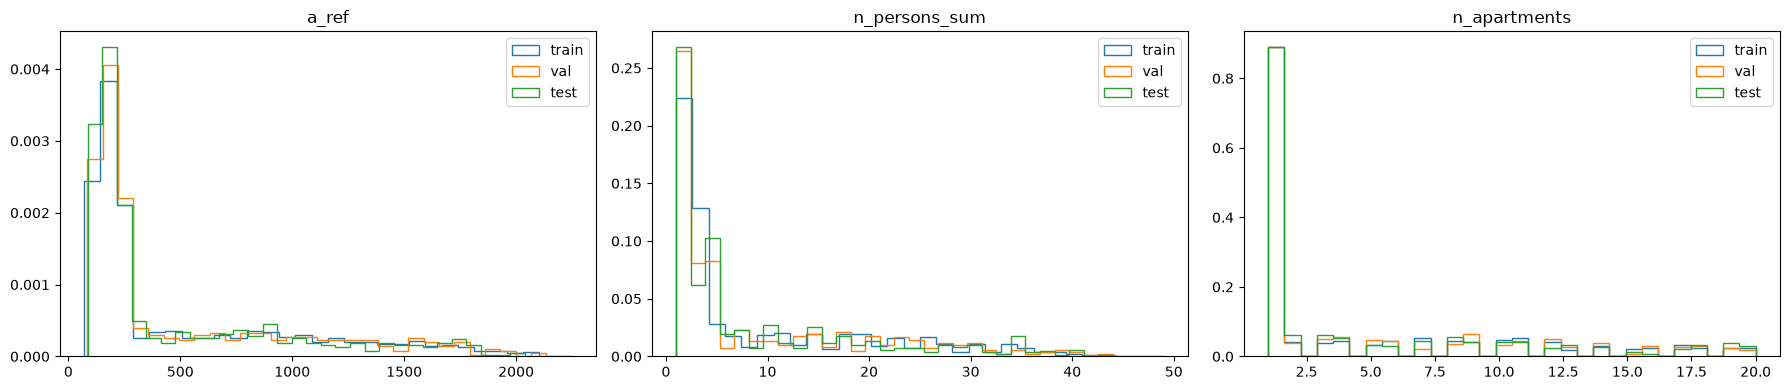

___buildingType___
              original  train   val  test  holdout_building  holdout_year  \
buildingType                                                                
AB                0.13   0.13  0.13  0.13               NaN          0.13   
MFH               0.31   0.31  0.31  0.31               NaN          0.31   
SFH               0.31   0.31  0.31  0.31               NaN          0.31   
TH                0.26   0.26  0.26  0.26               1.0          0.26   

              holdout_both  
buildingType                
AB                     NaN  
MFH                    NaN  
SFH                    NaN  
TH                     1.0  
Chi2=0.0000, p=1.0000, dof=6
___buildingAgeBin___
                original  train   val  test  holdout_building  holdout_year  \
buildingAgeBin                                                                
DE.01               0.05   0.05  0.05  0.05               NaN          0.05   
DE.02               0.10   0.10  0.10  0.10              

In [6]:
check_distr(split_dfs=split_dfs,cont_cols=rest_cols, cat_cols=strat_cols_test, row_cols=["year"])

## Move split files to directories

In [7]:
source_dir = Path(r"../data/raw/Generation")
target_root = Path(r"../data/split")

split_dirs = {
    "train": target_root/"train",
    "val": target_root/"val",
    "test": target_root/"test",
    "holdout_year": target_root/"test"/"holdout_year",
    "holdout_building": target_root/"test"/"holdout_building",
    "holdout_both": target_root/"test"/"holdout_both",
}

split_dfs = {
    "train": train_df, "val": val_df, "test": test_df,
    "holdout_building": holdout_building_df,
    "holdout_year": holdout_year_df,
    "holdout_both": holdout_both_df,
}

#move_split_data(manifest, source_dir,split_dirs, split_dfs)

## Calculate Parameters for normalization once per resolution

In [8]:
# ToDo calculate all parameters in a loop .

ALL_COLS = [
    "T",
    "Occupancy Home Active",
    "Occupancy Home Not Active",
    "Electricity Load",
    "Hot Water Load",
    "Heating Load",
]

TS_AGG = {
    "T": "first",
    "Occupancy Home Active": "first",
    "Occupancy Home Not Active": "first",
    "Electricity Load": "mean",
    "Hot Water Load": "mean",
    "Heating Load": "mean",
    "Off Day": "max"
}


columns = ["Electricity Load", "Hot Water Load","Heating Load","Occupancy Home Active", "Occupancy Home Not Active","T","Off Day"]
NORM_BY_COL = {"Electricity Load": "n_persons_sum"}#"Electricity Load": "n_persons_sum","Heating Load": "a_ref"
train_df_exist, train_idx_missing = existing_filter(train_df, split_dirs["train"])
train_factors = build_norm_factors(train_df, columns, NORM_BY_COL)
preprocessor = PreprocessStaticCols(static_cat_cols=[],static_cont_cols=[], static_bool_cols=[]).fit(train_df_exist)
train_files, train_run_ids, train_static = normalizestatic(train_df_exist,split_dirs["train"],preprocessor)

Missing Files: 7185
Existing Files: 1004
Total: 8189


## Calculate all the Sacler Stats once

In [9]:
STATS_DIR = Path("../data/stats/scalerstats")
STATS_DIR.mkdir(parents=True, exist_ok=True)
DYN_COLS = columns
RESOLUTIONS = ["1min","5min","10min","15min", "1h"]
NORM_VARIANTS = {
    "none": {},
    "elec_sh_scale": {"Electricity Load": "n_persons_sum","Heating Load": "a_ref"},
    "elec_dhw_sh_scale": {"Electricity Load": "n_persons_sum","Hot Water Load": "n_persons_sum","Heating Load": "a_ref"},
    "all_area": {"Electricity Load": "a_ref","Hot Water Load": "a_ref","Heating Load": "a_ref"},
    "all_sum_n_persons": {"Electricity Load": "n_persons_sum","Hot Water Load": "n_persons_sum","Heating Load": "n_persons_sum"},
}

def stats_path(res, norm_name, norm_by_col, cols, run_ids):
    key = json.dumps({"cols": cols, "norm": norm_by_col, "runs": sorted(run_ids)},
                     sort_keys=True, default=str)
    h = hashlib.sha256(key.encode()).hexdigest()[:8]
    return STATS_DIR / f"stats_{norm_name}_{res}_{h}.npz"


for res, (norm_name, norm_by_col) in product(RESOLUTIONS, NORM_VARIANTS.items()):
    path = stats_path(res, norm_name, norm_by_col, DYN_COLS, train_run_ids)
    if path.exists():
        print(f"skip {path.name}")
        continue

    factors = build_norm_factors(train_df, DYN_COLS, norm_by_col) if norm_by_col else None
    stats = calc_scaler_stats(train_files, train_run_ids, DYN_COLS, TS_AGG,resolution=res, norm_factors=factors)
    save_stats(path, res, DYN_COLS, stats, norm_by_col=norm_by_col)

skip stats_none_1min_deb078f6.npz
skip stats_elec_sh_scale_1min_af64f9e9.npz
skip stats_elec_dhw_sh_scale_1min_a152b8c8.npz
skip stats_all_area_1min_523849fc.npz
skip stats_all_sum_n_persons_1min_5928bd9d.npz


  0%|          | 0/1004 [00:00<?, ?it/s]

  0%|          | 0/1004 [00:00<?, ?it/s]

  0%|          | 0/1004 [00:00<?, ?it/s]

  0%|          | 0/1004 [00:00<?, ?it/s]

  0%|          | 0/1004 [00:00<?, ?it/s]

skip stats_none_10min_deb078f6.npz
skip stats_elec_sh_scale_10min_af64f9e9.npz
skip stats_elec_dhw_sh_scale_10min_a152b8c8.npz
skip stats_all_area_10min_523849fc.npz
skip stats_all_sum_n_persons_10min_5928bd9d.npz
skip stats_none_15min_deb078f6.npz
skip stats_elec_sh_scale_15min_af64f9e9.npz
skip stats_elec_dhw_sh_scale_15min_a152b8c8.npz
skip stats_all_area_15min_523849fc.npz
skip stats_all_sum_n_persons_15min_5928bd9d.npz
skip stats_none_1h_deb078f6.npz
skip stats_elec_sh_scale_1h_af64f9e9.npz
skip stats_elec_dhw_sh_scale_1h_a152b8c8.npz
skip stats_all_area_1h_523849fc.npz
skip stats_all_sum_n_persons_1h_5928bd9d.npz
